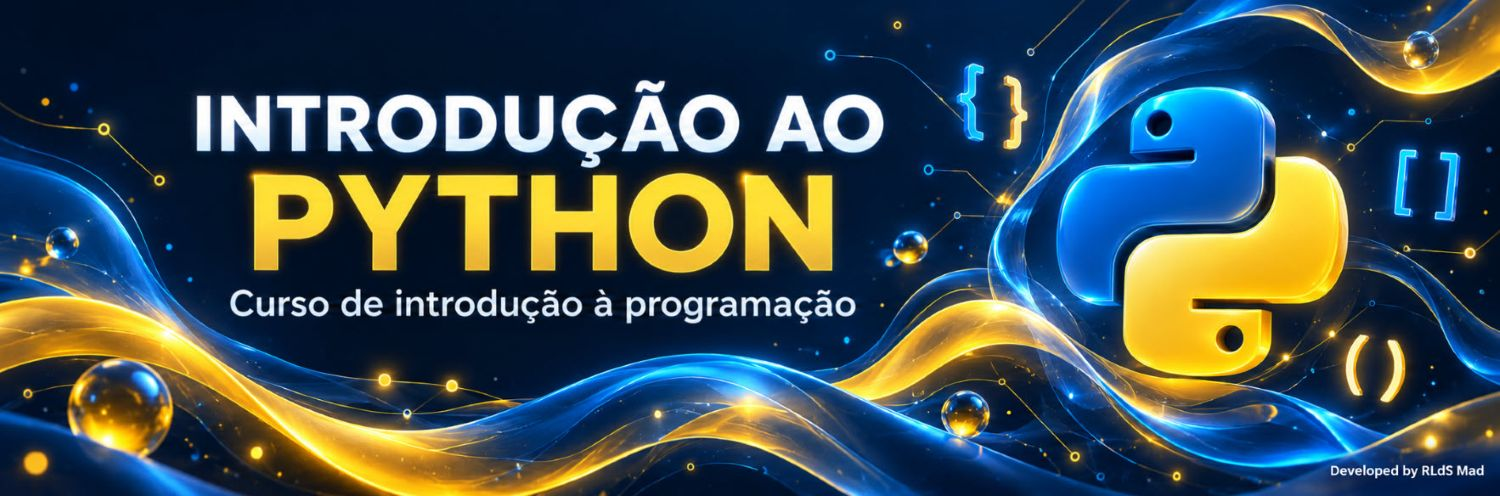

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python/nivel_3_ia/N3_05_PyTorch_Fundamentos.ipynb)


# Nível IA · Módulo 5 – PyTorch: fundamentos
## Do NumPy ao PyTorch, e de volta ao caso de estudo

No módulo anterior construíste uma rede neuronal de raiz: a propagação para a frente, a retropropagação, a descida do gradiente e os mini-lotes, tudo escrito à mão em NumPy. Neste módulo fazes o mesmo com o **PyTorch**, uma das bibliotecas de *deep learning* mais usadas na investigação e na indústria. Vais ver que cada peça do N3_04 tem um equivalente direto, e que a mais trabalhosa, a retropropagação, passa a ser **uma linha**: `perda.backward()`.

No fim, aplicas uma rede neuronal ao caso de estudo do abandono de clientes (módulo N3_03) e comparas com os modelos clássicos. O resultado é uma lição importante sobre quando vale (e quando não vale) a pena usar redes neuronais.

> **Objetivos:** criar e manipular tensores, e convertê-los de e para NumPy; usar o *autograd* para calcular gradientes e confirmá-los com os do N3_04; definir redes com `nn.Module` e `nn.Sequential`, escolher a função de perda e o otimizador; usar `Dataset` e `DataLoader`; escrever o ciclo de treino e avaliação típico, com `model.train()`, `model.eval()` e `torch.no_grad()`; garantir reprodutibilidade, usar a GPU quando existe, e guardar e carregar modelos; avaliar com honestidade uma rede neuronal em dados tabulares.

**Pré-requisitos:** módulo N3_04 (redes neuronais de raiz), classes e herança (capítulo 20), iteradores, gestores de contexto e anotações de tipo (capítulo 25) e o processo KDD (módulo N3_03).

| Secção | Tema |
| --- | --- |
| 0. Preparação | instalar e importar o PyTorch; CPU ou GPU |
| 1. Tensores | o «array» do PyTorch |
| 2. *Autograd* | gradientes automáticos, conferidos com o N3_04 |
| 3. Redes com `nn.Module` | camadas, perdas e otimizadores |
| 4. `Dataset` e `DataLoader` | dados em mini-lotes |
| 5. O ciclo de treino | `train`/`eval`, `no_grad`, paragem antecipada, guardar o modelo |
| 6. Caso de estudo | o abandono de clientes do N3_03, com uma rede neuronal |
| 7. Experimenta | três exercícios com solução |


## 0. Preparação

### 0.1 Instalar o PyTorch

No **Colab**, o PyTorch já vem instalado. No teu computador, instala-o no ambiente virtual do projeto (anexo A2). O site [pytorch.org](https://pytorch.org/get-started/locally/) gera o comando certo para o teu sistema; para uma instalação só com CPU, mais pequena:

```text
python -m pip install torch --index-url https://download.pytorch.org/whl/cpu
```

A célula seguinte confirma se o PyTorch está disponível e explica o que fazer se não estiver.


In [1]:
# Executar esta célula

try:
    import torch
    print(f"PyTorch {torch.__version__} disponível.")
except ImportError:
    print("O PyTorch não está instalado neste ambiente.\n"
          "No Colab: Ambiente de execução → Reiniciar sessão.\n"
          "No teu computador: python -m pip install torch --index-url https://download.pytorch.org/whl/cpu")

PyTorch 2.15.0+cu132 disponível.


### 0.2 Bibliotecas, sementes e dispositivo

O PyTorch pode fazer os cálculos no processador (**CPU**) ou numa placa gráfica (**GPU**, com CUDA), que é muito mais rápida para redes grandes. No Colab, ativa-se em *Ambiente de execução → Alterar tipo de ambiente de execução → GPU*. Neste módulo, as redes são pequenas e a CPU chega perfeitamente; o código funciona nas duas.

Para que os resultados se possam repetir, fixamos as **sementes** do NumPy e do PyTorch.


In [2]:
# Executar esta célula

import copy
import json
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.compose import ColumnTransformer
from sklearn.datasets import make_moons
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from torch import nn
from torch.utils.data import DataLoader, Dataset, TensorDataset

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
torch.manual_seed(0)
np.random.seed(0)

dispositivo = "cuda" if torch.cuda.is_available() else "cpu"
print(f"PyTorch {torch.__version__} | dispositivo: {dispositivo}")

PyTorch 2.15.0+cu132 | dispositivo: cpu


## 1. Tensores

Um **tensor** é o equivalente, no PyTorch, a um *array* do NumPy: uma tabela de números com uma ou mais dimensões. A sintaxe é muito parecida. As diferenças importantes são três: os tensores podem viver na **GPU**, podem **lembrar-se das operações** que os criaram (para calcular gradientes, secção 2), e o tipo por omissão dos decimais é `float32`, e não `float64`.

### 1.1 Criar tensores e conhecer a sua forma

| NumPy | PyTorch |
| --- | --- |
| `np.array([[1, 2], [3, 4]])` | `torch.tensor([[1, 2], [3, 4]])` |
| `np.zeros((2, 3))`, `np.ones(...)` | `torch.zeros(2, 3)`, `torch.ones(...)` |
| `np.arange(6)`, `np.linspace(0, 1, 5)` | `torch.arange(6)`, `torch.linspace(0, 1, 5)` |
| `rng.normal(size=(2, 3))` | `torch.randn(2, 3)` |
| `a.shape`, `a.dtype` | `t.shape`, `t.dtype`, e também `t.device` |
| `a.reshape(3, 2)` | `t.reshape(3, 2)` (ou `t.view(3, 2)`) |
| `a @ b`, `a.T`, `a.sum(axis=0)` | `t @ u`, `t.T`, `t.sum(dim=0)` |


In [3]:
# Executar esta célula

t = torch.tensor([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0]])
print(t)
print("forma:", t.shape, "| tipo:", t.dtype, "| dispositivo:", t.device)
print("soma por coluna:", t.sum(dim=0))
print("média:", t.mean().item())                     # .item() converte um tensor com um só valor num número Python
print("produto t @ t.T:\n", t @ t.T)
print("broadcasting, t + [10, 20, 30]:\n", t + torch.tensor([10.0, 20.0, 30.0]))

tensor([[1., 2., 3.],
        [4., 5., 6.]])
forma: torch.Size([2, 3]) | tipo: torch.float32 | dispositivo: cpu
soma por coluna: tensor([5., 7., 9.])
média: 3.5
produto t @ t.T:
 tensor([[14., 32.],
        [32., 77.]])
broadcasting, t + [10, 20, 30]:
 tensor([[11., 22., 33.],
        [14., 25., 36.]])


### 1.2 De e para NumPy

`torch.from_numpy(a)` e `t.numpy()` convertem nos dois sentidos **sem copiar os dados**: o tensor e o *array* partilham a mesma memória, por isso alterar um altera o outro. Se precisares de uma cópia independente, usa `torch.tensor(a)` ou `t.numpy().copy()`.


In [4]:
# Executar esta célula

a = np.array([1.0, 2.0, 3.0])
partilhado = torch.from_numpy(a)
copia = torch.tensor(a)
a[0] = 100
print("from_numpy (partilha a memória):", partilhado)
print("torch.tensor (cópia):           ", copia)
print("tipo vindo do NumPy:", partilhado.dtype)

from_numpy (partilha a memória): tensor([100.,   2.,   3.], dtype=torch.float64)
torch.tensor (cópia):            tensor([1., 2., 3.], dtype=torch.float64)
tipo vindo do NumPy: torch.float64


Repara no tipo: o NumPy usa `float64` por omissão, e o tensor herda-o. Mas as camadas do PyTorch usam `float32`. Misturar os dois tipos é um dos erros mais frequentes:


In [5]:
# Executar esta célula

# ⚠️ Esta célula gera um erro de propósito (RuntimeError). Lê a mensagem e continua.
camada = nn.Linear(3, 1)                             # pesos em float32
camada(torch.from_numpy(np.array([[1.0, 2.0, 3.0]])))   # entrada em float64

RuntimeError: mat1 and mat2 must have the same dtype, but got Double and Float

A solução é converter na origem: `torch.tensor(X, dtype=torch.float32)` ou `torch.from_numpy(X).float()`. Para levar um tensor para a GPU usa-se `.to(dispositivo)`, e os tensores de uma mesma operação têm de estar todos no mesmo dispositivo.


In [6]:
# Executar esta célula

x = torch.from_numpy(np.array([[1.0, 2.0, 3.0]])).float().to(dispositivo)
print(x.dtype, x.device, "→", camada.to(dispositivo)(x))

torch.float32 cpu → tensor([[-1.2353]], grad_fn=<AddmmBackward0>)


## 2. *Autograd*: gradientes automáticos

### 2.1 O exemplo da regra da cadeia, outra vez

Na secção 5.1 do N3_04 calculaste à mão, elo a elo, a derivada da perda $L = (\sigma(wx + b) - y)^2$ em ordem a $w$, com $x = 2$, $y = 1$, $w = 0{,}5$ e $b = -0{,}3$. O resultado foi $-0{,}29427$.

No PyTorch, basta marcar os parâmetros com `requires_grad=True`: o tensor passa a registar todas as operações feitas com ele (o **grafo de cálculo**). Depois, `L.backward()` percorre esse grafo de trás para a frente, aplicando a regra da cadeia, e guarda cada derivada no atributo `.grad`.


In [7]:
# Executar esta célula

x, y = torch.tensor(2.0), torch.tensor(1.0)
w = torch.tensor(0.5, requires_grad=True)
b = torch.tensor(-0.3, requires_grad=True)

L = (torch.sigmoid(w * x + b) - y) ** 2              # para a frente: o grafo é registado
L.backward()                                         # para trás: a regra da cadeia, automática
print(f"L = {L.item():.5f}")
print(f"dL/dw = {w.grad.item():.5f}   (no N3_04, à mão: -0.29427)")
print(f"dL/db = {b.grad.item():.5f}")

L = 0.11010
dL/dw = -0.29427   (no N3_04, à mão: -0.29427)
dL/db = -0.14713


### 2.2 Os gradientes acumulam-se

Um pormenor que apanha toda a gente: se chamares `backward()` outra vez, o PyTorch **soma** os novos gradientes aos que já estão em `.grad`, em vez de os substituir. Por isso, no ciclo de treino, os gradientes são postos a zero antes de cada passo (`otimizador.zero_grad()`, secção 3).


In [8]:
# Executar esta célula

L = (torch.sigmoid(w * x + b) - y) ** 2
L.backward()
print(f"Depois de um segundo backward(): dL/dw = {w.grad.item():.5f} (o dobro!)")
w.grad.zero_()
b.grad.zero_()
print("Depois de zero_():", w.grad.item())

Depois de um segundo backward(): dL/dw = -0.58854 (o dobro!)
Depois de zero_(): 0.0


### 2.3 Conferir com a retropropagação do N3_04

Agora o teste a sério: os gradientes de uma **rede inteira**. A função seguinte é a retropropagação do N3_04 (secção 5.2), em NumPy. Damos à rede do PyTorch exatamente os mesmos pesos, calculamos a perda e chamamos `backward()`. Usamos `float64` nos dois lados para a comparação ser exata.

Um pormenor: o `nn.Linear` guarda a matriz de pesos **transposta** em relação à nossa. No N3_04, `W1` tinha forma (entradas, escondidos) = (2, 16); no PyTorch, `weight` tem forma (saídas, entradas) = (16, 2). Por isso comparamos com `.T`.


In [9]:
# Executar esta célula

def gradientes_numpy(W1, b1, W2, b2, X, y):
    """Retropropagação do N3_04 (ReLU na camada escondida, sigmoide e entropia cruzada na saída)."""
    Z1 = X @ W1 + b1
    A1 = np.maximum(0, Z1)
    A2 = 1 / (1 + np.exp(-(A1 @ W2 + b2)))
    dZ2 = (A2 - y.reshape(-1, 1)) / len(X)
    dZ1 = (dZ2 @ W2.T) * (Z1 > 0)
    return {"W1": X.T @ dZ1, "b1": dZ1.sum(axis=0), "W2": A1.T @ dZ2, "b2": dZ2.sum(axis=0)}


X_np, y_np = make_moons(n_samples=50, noise=0.2, random_state=0)
rng = np.random.default_rng(0)
W1, b1 = rng.normal(0, 1, (2, 16)), rng.normal(0, 0.1, 16)
W2, b2 = rng.normal(0, 0.25, (16, 1)), rng.normal(0, 0.1, 1)
g_np = gradientes_numpy(W1, b1, W2, b2, X_np, y_np)

camada1, camada2 = nn.Linear(2, 16).double(), nn.Linear(16, 1).double()
with torch.no_grad():                                # copiar os pesos sem registar no grafo
    camada1.weight.copy_(torch.tensor(W1.T))
    camada1.bias.copy_(torch.tensor(b1))
    camada2.weight.copy_(torch.tensor(W2.T))
    camada2.bias.copy_(torch.tensor(b2))

saida = torch.sigmoid(camada2(torch.relu(camada1(torch.tensor(X_np)))))
perda = nn.functional.binary_cross_entropy(saida, torch.tensor(y_np, dtype=torch.float64).reshape(-1, 1))
perda.backward()

comparacao = {"W1": camada1.weight.grad.T, "b1": camada1.bias.grad,
              "W2": camada2.weight.grad.T, "b2": camada2.bias.grad}
for nome, g_torch in comparacao.items():
    print(f"{nome}: iguais? {np.allclose(g_torch.numpy(), g_np[nome])}")

W1: iguais? True
b1: iguais? True
W2: iguais? True
b2: iguais? True


Os gradientes são iguais: o `backward()` faz exatamente a retropropagação que escreveste no N3_04, mas para **qualquer** rede, com qualquer número de camadas.

### 2.4 Desligar o registo: `torch.no_grad()` e `detach()`

Registar o grafo gasta memória e tempo. Quando só queremos **usar** a rede (avaliar, prever) ou mexer nos pesos à mão, como acima, desligamos o registo com o gestor de contexto `torch.no_grad()` (capítulo 25). Para um único tensor, `t.detach()` devolve uma cópia sem ligação ao grafo, o que é preciso, por exemplo, para o converter em NumPy.


In [10]:
# Executar esta célula

with torch.no_grad():
    sem_grafo = camada1(torch.tensor(X_np))
print("Dentro de no_grad, requires_grad =", sem_grafo.requires_grad)
print("Com detach().numpy():", saida.detach().numpy()[:3].ravel().round(3))

Dentro de no_grad, requires_grad = False
Com detach().numpy(): [0.512 0.521 0.527]


## 3. Redes com `nn.Module`: camadas, perdas e otimizadores

### 3.1 Definir a rede

Há duas formas de definir uma rede. A mais curta, **`nn.Sequential`**, serve quando as camadas se aplicam umas a seguir às outras. A mais geral é uma **classe que herda de `nn.Module`** (capítulo 20): as camadas criam-se no `__init__` e o cálculo escreve-se no método `forward`. O PyTorch encontra sozinho todos os parâmetros das camadas.

Uma diferença em relação ao N3_04: a última camada **não tem sigmoide**. A rede devolve o valor $z$ antes da sigmoide (os ***logits***), e a função de perda `nn.BCEWithLogitsLoss` aplica a sigmoide e a entropia cruzada de uma só vez. É numericamente mais estável (evita o `log(0)` que no N3_04 resolvemos com `np.clip`). Para obter probabilidades, aplica-se `torch.sigmoid` à saída.


In [11]:
# Executar esta célula

class RedeLuas(nn.Module):
    """A rede do N3_04: 2 entradas → 16 ReLU → 1 saída (logit)."""

    def __init__(self, n_entradas: int = 2, n_escondidos: int = 16):
        super().__init__()
        self.escondida = nn.Linear(n_entradas, n_escondidos)
        self.saida = nn.Linear(n_escondidos, 1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.saida(torch.relu(self.escondida(x)))


torch.manual_seed(0)
rede = RedeLuas()
sequencial = nn.Sequential(nn.Linear(2, 16), nn.ReLU(), nn.Linear(16, 1))     # a mesma arquitetura
print(rede)
for nome, p in rede.named_parameters():
    print(f"{nome:<18} {tuple(p.shape)}")
print("Parâmetros:", sum(p.numel() for p in rede.parameters()), "(no N3_04 também eram 65)")

RedeLuas(
  (escondida): Linear(in_features=2, out_features=16, bias=True)
  (saida): Linear(in_features=16, out_features=1, bias=True)
)
escondida.weight   (16, 2)
escondida.bias     (16,)
saida.weight       (1, 16)
saida.bias         (1,)
Parâmetros: 65 (no N3_04 também eram 65)


### 3.2 Perdas e otimizadores

| Tarefa | Saída da rede | Função de perda |
| --- | --- | --- |
| classificação binária | 1 *logit* | `nn.BCEWithLogitsLoss()` |
| classificação com várias classes | 1 *logit* por classe | `nn.CrossEntropyLoss()` |
| regressão | 1 valor | `nn.MSELoss()` ou `nn.L1Loss()` |

O **otimizador** aplica a descida do gradiente aos parâmetros. `torch.optim.SGD` é a descida do gradiente simples do N3_04 (com `momentum=0.9`, a do exercício 3 do N3_04); `torch.optim.Adam` adapta a taxa de aprendizagem a cada parâmetro e é, muitas vezes, a melhor escolha para começar. O argumento `weight_decay` faz a regularização L2.

Um passo de treino tem sempre as mesmas cinco linhas:


In [12]:
# Executar esta célula

X_luas, y_luas = make_moons(n_samples=600, noise=0.25, random_state=42)
X_t = torch.tensor(X_luas, dtype=torch.float32)
y_t = torch.tensor(y_luas, dtype=torch.float32).reshape(-1, 1)

perda_fn = nn.BCEWithLogitsLoss()
otimizador = torch.optim.SGD(rede.parameters(), lr=0.1)

for passo in range(3):
    logits = rede(X_t)                    # 1. propagar para a frente
    perda = perda_fn(logits, y_t)         # 2. calcular a perda
    otimizador.zero_grad()                # 3. limpar os gradientes anteriores
    perda.backward()                      # 4. retropropagação
    otimizador.step()                     # 5. atualizar os pesos
    print(f"passo {passo + 1}: perda {perda.item():.4f}")

passo 1: perda 0.6799
passo 2: perda 0.6739
passo 3: perda 0.6681


## 4. `Dataset` e `DataLoader`

No N3_04, um gerador entregava os mini-lotes. O PyTorch separa esse trabalho em duas peças:

- um **`Dataset`** sabe quantos exemplos há (`__len__`) e devolve o exemplo número `i` (`__getitem__`). Para dados que já estão em tensores, `TensorDataset(X, y)` faz isso sozinho; para dados que vêm de ficheiros (imagens, textos), escreve-se uma classe própria;
- um **`DataLoader`** pega no `Dataset` e entrega **mini-lotes**, baralhados se `shuffle=True`. É um **iterável** (capítulo 25): percorre-se com `for`, e cada `for` cria um iterador novo, com uma nova ordem.

### 4.1 Um `Dataset` próprio

Para perceber o que o `TensorDataset` faz, escrevemos o nosso, com os dois métodos especiais:


In [13]:
# Executar esta célula

class DadosTabela(Dataset):
    """Um exemplo = (atributos, alvo), já em tensores float32."""

    def __init__(self, X: np.ndarray, y: np.ndarray):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32).reshape(-1, 1)

    def __len__(self) -> int:
        return len(self.X)

    def __getitem__(self, i: int) -> tuple[torch.Tensor, torch.Tensor]:
        return self.X[i], self.y[i]


X_treino, X_resto, y_treino, y_resto = train_test_split(X_luas, y_luas, test_size=0.4, stratify=y_luas, random_state=42)
X_val, X_teste, y_val, y_teste = train_test_split(X_resto, y_resto, test_size=0.5, stratify=y_resto, random_state=42)

dados_treino = DadosTabela(X_treino, y_treino)
print("Exemplos:", len(dados_treino), "| exemplo 0:", dados_treino[0])

gerador = torch.Generator().manual_seed(0)           # baralhar sempre da mesma maneira
carregador = DataLoader(dados_treino, batch_size=32, shuffle=True, generator=gerador)
X_lote, y_lote = next(iter(carregador))              # o primeiro lote
print(f"{len(carregador)} lotes por época | formas do lote: {tuple(X_lote.shape)}, {tuple(y_lote.shape)}")

Exemplos: 360 | exemplo 0: (tensor([-0.5898,  1.2957]), tensor([0.]))
12 lotes por época | formas do lote: (32, 2), (32, 1)


São os mesmos números do N3_04: 360 exemplos de treino, 12 lotes de 32 por época (o último mais pequeno). Para os conjuntos de validação e teste usamos o `TensorDataset`, que faz o mesmo que a nossa classe.

Em problemas grandes, o `DataLoader` faz mais: lê os dados em paralelo (`num_workers`), e permite um `Dataset` que só carrega cada imagem do disco quando ela é pedida, sem nunca ter o conjunto todo na memória.


## 5. O ciclo de treino

### 5.1 `train()`, `eval()` e `torch.no_grad()`

Algumas camadas comportam-se de maneira diferente no treino e na avaliação. A mais comum é o **`nn.Dropout`**, que durante o treino «desliga» ao acaso uma fração dos neurónios em cada passo (é uma forma de regularização), mas que na avaliação deve deixar passar tudo. O método `modelo.train()` liga o modo de treino; `modelo.eval()` liga o de avaliação.


In [14]:
# Executar esta célula

torch.manual_seed(0)
com_dropout = nn.Sequential(nn.Linear(2, 8), nn.ReLU(), nn.Dropout(p=0.5), nn.Linear(8, 1))
x = torch.tensor([[0.5, 0.2]])

com_dropout.train()
print("modo train:", [round(com_dropout(x).item(), 3) for _ in range(4)], "← muda a cada chamada")
com_dropout.eval()
with torch.no_grad():
    print("modo eval: ", [round(com_dropout(x).item(), 3) for _ in range(4)], "← sempre igual")

modo train: [-0.111, 0.008, -0.149, -0.071] ← muda a cada chamada
modo eval:  [-0.228, -0.228, -0.228, -0.228] ← sempre igual


A regra prática: **`modelo.train()` antes de treinar, e `modelo.eval()` + `with torch.no_grad():` antes de avaliar ou prever.** Esquecer o `eval()` dá previsões aleatórias com dropout; esquecer o `no_grad()` gasta memória a registar um grafo que nunca vai ser usado.

### 5.2 Duas funções reutilizáveis

O ciclo de treino escreve-se quase sempre da mesma maneira. Separamo-lo em duas funções: uma que treina uma época e outra que avalia.


In [15]:
# Executar esta célula

def treinar_epoca(modelo: nn.Module, carregador: DataLoader, perda_fn, otimizador) -> float:
    """Uma época de treino; devolve a perda média."""
    modelo.train()
    total = 0.0
    for X_lote, y_lote in carregador:
        X_lote, y_lote = X_lote.to(dispositivo), y_lote.to(dispositivo)
        perda = perda_fn(modelo(X_lote), y_lote)
        otimizador.zero_grad()
        perda.backward()
        otimizador.step()
        total += perda.item() * len(X_lote)
    return total / len(carregador.dataset)


def avaliar(modelo: nn.Module, carregador: DataLoader, perda_fn) -> tuple[float, float]:
    """Perda média e exatidão, sem registar gradientes."""
    modelo.eval()
    total, certos = 0.0, 0
    with torch.no_grad():
        for X_lote, y_lote in carregador:
            X_lote, y_lote = X_lote.to(dispositivo), y_lote.to(dispositivo)
            logits = modelo(X_lote)
            total += perda_fn(logits, y_lote).item() * len(X_lote)
            certos += ((logits > 0).float() == y_lote).sum().item()     # logit > 0 ⇔ probabilidade > 0,5
    n = len(carregador.dataset)
    return total / n, certos / n

### 5.3 Treinar a rede das meias-luas

Treinamos a mesma rede do N3_04 (16 neurónios, SGD com taxa 0,1, lotes de 32, 300 épocas), com os mesmos dados, e acompanhamos as curvas de treino e validação.


Exatidão: validação 95.0% | teste 91.7% (N3_04: 92,5 % no teste)


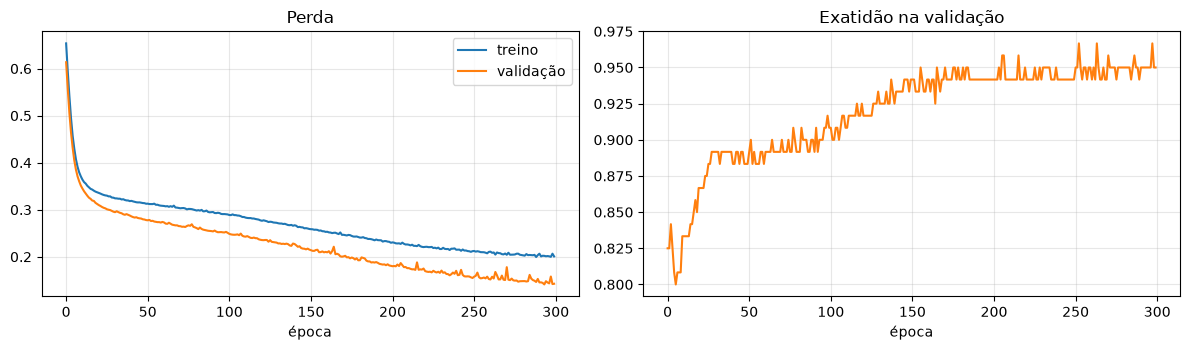

In [16]:
# Executar esta célula

def carregador_de(X, y, **opcoes) -> DataLoader:
    return DataLoader(TensorDataset(torch.tensor(X, dtype=torch.float32),
                                    torch.tensor(y, dtype=torch.float32).reshape(-1, 1)), **opcoes)


treino_dl = carregador_de(X_treino, y_treino, batch_size=32, shuffle=True, generator=torch.Generator().manual_seed(0))
val_dl = carregador_de(X_val, y_val, batch_size=256)
teste_dl = carregador_de(X_teste, y_teste, batch_size=256)

torch.manual_seed(0)
modelo = RedeLuas().to(dispositivo)
perda_fn = nn.BCEWithLogitsLoss()
otimizador = torch.optim.SGD(modelo.parameters(), lr=0.1)

historico = {"treino": [], "val": [], "exat_val": []}
for epoca in range(300):
    historico["treino"].append(treinar_epoca(modelo, treino_dl, perda_fn, otimizador))
    perda_val, exat_val = avaliar(modelo, val_dl, perda_fn)
    historico["val"].append(perda_val)
    historico["exat_val"].append(exat_val)

print(f"Exatidão: validação {historico['exat_val'][-1]:.1%} | teste {avaliar(modelo, teste_dl, perda_fn)[1]:.1%} "
      "(N3_04: 92,5 % no teste)")
fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
axs[0].plot(historico["treino"], label="treino")
axs[0].plot(historico["val"], label="validação")
axs[0].set(title="Perda", xlabel="época")
axs[0].legend()
axs[1].plot(historico["exat_val"], color="C1")
axs[1].set(title="Exatidão na validação", xlabel="época")
plt.tight_layout()
plt.show()

O resultado fica ao nível do N3_04, com uma fração do código: a classe da rede tem 8 linhas e o passo de treino tem 5. Os valores não são exatamente iguais porque a inicialização dos pesos do `nn.Linear` e a ordem dos lotes são diferentes das nossas.

Vale a pena olhar também para a fronteira de decisão. Para usar a rede com NumPy, convertemos a grelha em tensor e as probabilidades de volta em *array*:


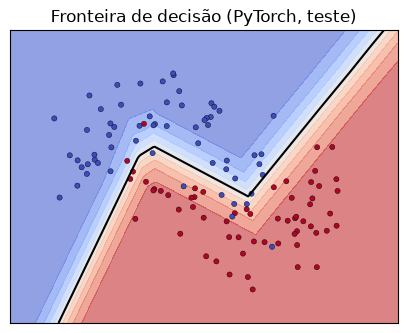

In [17]:
# Executar esta célula

def prever_proba(modelo: nn.Module, X: np.ndarray) -> np.ndarray:
    modelo.eval()
    with torch.no_grad():
        logits = modelo(torch.tensor(X, dtype=torch.float32).to(dispositivo))
    return torch.sigmoid(logits).cpu().numpy().ravel()          # .cpu(): se estiver na GPU, traz para a CPU


x1, x2 = np.meshgrid(np.linspace(-1.8, 2.8, 250), np.linspace(-1.4, 1.9, 250))
prob = prever_proba(modelo, np.c_[x1.ravel(), x2.ravel()]).reshape(x1.shape)
plt.figure(figsize=(5, 3.8))
plt.contourf(x1, x2, prob, levels=np.linspace(0, 1, 11), cmap="coolwarm", alpha=0.6)
plt.contour(x1, x2, prob, levels=[0.5], colors="k")
plt.scatter(X_teste[:, 0], X_teste[:, 1], c=y_teste, cmap="coolwarm", s=14, edgecolor="k", linewidths=0.3)
plt.title("Fronteira de decisão (PyTorch, teste)")
plt.xticks([]), plt.yticks([])
plt.show()

### 5.4 Paragem antecipada e guardar o modelo

Num modelo PyTorch, os parâmetros vivem num dicionário, o **`state_dict()`**. Para a paragem antecipada, guardamos uma cópia do `state_dict` sempre que a perda de validação melhora, e repomo-la no fim com `load_state_dict`. Para guardar o modelo num ficheiro usa-se `torch.save(modelo.state_dict(), "ficheiro.pt")`; para o recuperar, cria-se um modelo com a mesma arquitetura e carregam-se os pesos.


In [18]:
# Executar esta célula

def treinar(modelo, treino_dl, val_dl, perda_fn, otimizador, epocas=500, paciencia=30) -> dict:
    """Ciclo de treino com paragem antecipada; repõe os melhores pesos no fim."""
    historico = {"treino": [], "val": []}
    melhor_perda, melhor_estado, melhor_epoca = float("inf"), None, 0
    for epoca in range(1, epocas + 1):
        historico["treino"].append(treinar_epoca(modelo, treino_dl, perda_fn, otimizador))
        perda_val, _ = avaliar(modelo, val_dl, perda_fn)
        historico["val"].append(perda_val)
        if perda_val < melhor_perda:
            melhor_perda, melhor_estado, melhor_epoca = perda_val, copy.deepcopy(modelo.state_dict()), epoca
        elif epoca - melhor_epoca >= paciencia:
            break
    modelo.load_state_dict(melhor_estado)
    print(f"Treino parado na época {epoca}; melhores pesos da época {melhor_epoca} "
          f"(perda de validação {melhor_perda:.4f}).")
    return historico


torch.manual_seed(0)
modelo_adam = RedeLuas().to(dispositivo)
hist_adam = treinar(modelo_adam, treino_dl, val_dl, perda_fn, torch.optim.Adam(modelo_adam.parameters(), lr=0.01))

torch.save(modelo_adam.state_dict(), "rede_luas.pt")
recuperado = RedeLuas().to(dispositivo)
recuperado.load_state_dict(torch.load("rede_luas.pt", weights_only=True))
print("Modelo recuperado dá as mesmas previsões?",
      np.allclose(prever_proba(modelo_adam, X_teste), prever_proba(recuperado, X_teste)))
print(f"Exatidão no teste (Adam + paragem antecipada): {avaliar(recuperado, teste_dl, perda_fn)[1]:.1%}")

Treino parado na época 396; melhores pesos da época 366 (perda de validação 0.0981).
Modelo recuperado dá as mesmas previsões? True
Exatidão no teste (Adam + paragem antecipada): 94.2%


O `weights_only=True` diz ao `torch.load` que o ficheiro só tem pesos (tensores). É a forma segura: um ficheiro `.pt` arbitrário pode conter código, e só se deve carregar sem esta opção se vier de uma fonte de confiança.

**Experimenta:** acrescenta `weight_decay=1e-3` ao otimizador Adam e volta a treinar. A exatidão muda? E a época em que o treino pára?


In [19]:
# Executar esta célula

# Utiliza esta célula para as tuas experiências

## 6. Caso de estudo: o abandono de clientes, com uma rede neuronal

### 6.1 Os dados do N3_03

Voltamos à loja do módulo N3_03: prever que clientes cancelam o cartão no 4.º trimestre, a partir dos dados de janeiro a setembro. Para este notebook não depender do N3_03, a primeira célula volta a criar as três fontes (com a mesma semente, os dados são os mesmos), e a segunda repete, de forma compacta, as fases de seleção, limpeza e transformação do N3_03 (secção 7.3).


In [20]:
# Executar esta célula

import json
import sqlite3
from pathlib import Path

import numpy as np
import pandas as pd

PASTA = Path("dados_loja")
PASTA.mkdir(exist_ok=True)
rng = np.random.default_rng(2025)
N = 1500
DATA_REF = pd.Timestamp("2025-12-31")

# --- características «verdadeiras» de cada cliente (o mundo real, que não observamos diretamente)
ids = [f"C{i:04d}" for i in range(1, N + 1)]
idade = np.clip(rng.normal(42, 13, N), 18, 85).round()
cidade = rng.choice(["Lisboa", "Porto", "Braga", "Coimbra", "Faro", "Aveiro"], N,
                    p=[0.32, 0.24, 0.12, 0.12, 0.10, 0.10])
canal = rng.choice(["loja", "online", "app"], N, p=[0.40, 0.35, 0.25])
plano = rng.choice(["Básico", "Plus", "Premium"], N, p=[0.55, 0.30, 0.15])
registo = DATA_REF - pd.to_timedelta(rng.integers(200, 1800, N), unit="D")
reclamacoes = rng.poisson(np.where(rng.random(N) < 0.2, 2.5, 0.4))
satisfacao = np.clip(np.round(4.1 - 0.45 * reclamacoes + rng.normal(0, 0.8, N)), 1, 5)

nivel_plano = pd.Series(plano).map({"Básico": 0, "Plus": 1, "Premium": 2}).to_numpy()
logit = (-1.2 + 0.55 * reclamacoes - 0.55 * (satisfacao - 3) - 0.5 * nivel_plano
         - 0.012 * (idade - 42) + 0.45 * (canal == "online") - 0.25 * (canal == "app")
         + rng.normal(0, 0.6, N))
abandonou = rng.random(N) < 1 / (1 + np.exp(-logit))

# --- fonte 1: vendas (base de dados SQLite), ano de 2025
linhas = []
for i in range(N):
    taxa = 9 + 6 * nivel_plano[i] + 3 * (canal[i] == "app")
    if abandonou[i]:                                         # cancela no 4.º trimestre (dias 273 a 364)
        fim = int(rng.integers(273, 365))
        antes = rng.poisson(taxa * 0.75 * 180 / 365)             # 1.º semestre: compra um pouco menos
        depois = rng.poisson(taxa * 0.55 * (fim - 180) / 365)    # a seguir: compra ainda menos
        dias = np.sort(np.r_[rng.integers(0, 180, antes), rng.integers(180, fim, depois)])
    else:
        dias = np.sort(rng.integers(0, 365, rng.poisson(taxa)))
    for d in dias:
        valor = round(float(rng.lognormal(3.3 + 0.25 * nivel_plano[i], 0.6)), 2)
        cat = rng.choice(["mercearia", "casa", "eletrónica", "moda", "desporto"],
                         p=[0.40, 0.20, 0.12, 0.18, 0.10])
        linhas.append((ids[i], (pd.Timestamp("2025-01-01") + pd.Timedelta(days=int(d))).date().isoformat(), valor, cat))
vendas = pd.DataFrame(linhas, columns=["id_cliente", "data", "valor", "categoria"])
dev = rng.random(len(vendas)) < 0.03                                   # devoluções: valor negativo
vendas.loc[dev, "valor"] = -vendas.loc[dev, "valor"]
erro = rng.choice(len(vendas), 4, replace=False)                       # erros de registo
vendas.loc[erro, "valor"] = [99999.0, 45000.0, 99999.0, 0.0]
antigas = pd.DataFrame({"id_cliente": rng.choice(ids, 400), "data": "2024-11-15",
                        "valor": 30.0, "categoria": "mercearia"})      # vendas de 2024 (fora do período)
vendas = pd.concat([antigas, vendas], ignore_index=True)
vendas.insert(0, "id_venda", range(1, len(vendas) + 1))
with sqlite3.connect(PASTA / "loja.db") as con:
    vendas.to_sql("vendas", con, if_exists="replace", index=False)
con.close()

# --- fonte 2: ficha de clientes (CSV exportado do CRM), com «sujidade»
clientes = pd.DataFrame({
    "id_cliente": ids,
    "data_registo": registo.strftime("%Y-%m-%d"),
    "idade": idade,
    "cidade": cidade,
    "canal_preferido": canal,
    "plano": plano,
    "pais": "Portugal",
    "estado": np.where(abandonou, "cancelado", "ativo"),
})
sujo = clientes.copy()
k = rng.choice(N, 140, replace=False)
sujo.loc[k[:50], "cidade"] = sujo.loc[k[:50], "cidade"].str.upper()
sujo.loc[k[50:90], "cidade"] = " " + sujo.loc[k[50:90], "cidade"].str.lower() + " "
sujo.loc[k[90:100], "cidade"] = np.nan
sujo.loc[k[100:110], "plano"] = "basico"
sujo.loc[k[110:130], "idade"] = np.nan
sujo.loc[k[130:134], "idade"] = [230, 0, 410, -1]
sujo.loc[k[134:140], "estado"] = ["Cancelado", "ATIVO", "Ativo ", "cancelado ", "Ativo", "CANCELADO"]
sujo = pd.concat([sujo, sujo.sample(30, random_state=1)], ignore_index=True)   # duplicados
sujo = sujo.sample(frac=1, random_state=2).reset_index(drop=True)
sujo.to_csv(PASTA / "clientes.csv", index=False, encoding="utf-8")

# --- fonte 3: resposta de uma API de apoio ao cliente (JSON aninhado), só para quem contactou
registos = []
for i in range(N):
    if reclamacoes[i] == 0 and rng.random() < 0.35:
        continue                                                      # nunca contactou o apoio
    registos.append({
        "cliente": {"id": ids[i]},
        "contactos": {"reclamacoes": int(reclamacoes[i]), "pedidos_informacao": int(rng.poisson(1.2))},
        "satisfacao": None if rng.random() < 0.08 else int(satisfacao[i]),
    })
resposta = {"periodo": {"inicio": "2025-01-01", "fim": "2025-09-30"}, "pagina": 1,
            "total": len(registos), "resultados": registos}
(PASTA / "apoio_api.json").write_text(json.dumps(resposta, ensure_ascii=False, indent=1), encoding="utf-8")

print(f"Clientes: {len(sujo)} linhas | vendas: {len(vendas)} | registos de apoio: {len(registos)}")

Clientes: 1530 linhas | vendas: 18472 | registos de apoio: 1183


In [21]:
# Executar esta célula

def preparar_tabela(pasta: Path, inicio: str = "2025-01-01", fim: str = "2025-09-30") -> pd.DataFrame:
    """Fases 1 a 3 do N3_03: uma linha por cliente, com os atributos da janela de observação e o alvo."""
    corte = pd.Timestamp(fim)
    with sqlite3.connect(pasta / "loja.db") as con:
        v = pd.read_sql_query("SELECT id_cliente, data, valor, categoria FROM vendas WHERE data BETWEEN :i AND :f",
                              con, params={"i": inicio, "f": fim})
    con.close()
    v = v[(v["valor"] != 0) & (v["valor"].abs() <= 5000)].assign(data=lambda d: pd.to_datetime(d["data"]))

    c = pd.read_csv(pasta / "clientes.csv").drop_duplicates(subset="id_cliente")
    for col in ["cidade", "canal_preferido", "plano", "estado"]:
        c[col] = c[col].str.strip().str.lower().str.replace("á", "a")
    c.loc[~c["idade"].between(16, 100), "idade"] = np.nan

    api = json.loads((pasta / "apoio_api.json").read_text(encoding="utf-8"))
    apoio = pd.json_normalize(api["resultados"]).rename(columns={
        "cliente.id": "id_cliente", "contactos.reclamacoes": "reclamacoes",
        "contactos.pedidos_informacao": "pedidos_info"})

    compras = v[v["valor"] > 0]
    agg = compras.groupby("id_cliente").agg(n_compras=("valor", "size"), gasto_total=("valor", "sum"),
                                            ultima=("data", "max"), n_categorias=("categoria", "nunique"))
    agg["recencia_dias"] = (corte - agg.pop("ultima")).dt.days
    agg["n_devolucoes"] = v[v["valor"] < 0].groupby("id_cliente").size()

    t = (c.merge(agg, on="id_cliente", how="left", validate="one_to_one")
          .merge(apoio, on="id_cliente", how="left", validate="one_to_one"))
    zeros = ["n_compras", "gasto_total", "n_categorias", "n_devolucoes", "reclamacoes", "pedidos_info"]
    t[zeros] = t[zeros].fillna(0)
    t["recencia_dias"] = t["recencia_dias"].fillna((corte - pd.Timestamp(inicio)).days)
    t["ticket_medio"] = (t["gasto_total"] / t["n_compras"]).where(t["n_compras"] > 0, 0)
    t["antiguidade_dias"] = (corte - pd.to_datetime(t["data_registo"])).dt.days
    t["abandonou"] = (t["estado"] == "cancelado").astype(int)
    return t


tabela = preparar_tabela(PASTA)
print(tabela.shape, f"| taxa de abandono {tabela['abandonou'].mean():.1%}")

(1500, 19) | taxa de abandono 25.6%


### 6.2 Pré-processamento e tensores

Usamos os mesmos atributos e o mesmo pré-processamento do N3_03 (imputar, padronizar, one-hot e ordinal), ajustado **só com o treino**. Desta vez separamos três conjuntos: treino (60 %), validação (20 %, para a paragem antecipada) e teste (20 %, usado uma vez no fim). O resultado do `ColumnTransformer` é um *array* NumPy, que convertemos em tensores através dos `DataLoader`.


In [22]:
# Executar esta célula

NUMERICAS = ["idade", "antiguidade_dias", "n_compras", "gasto_total", "ticket_medio", "recencia_dias",
             "n_categorias", "n_devolucoes", "reclamacoes", "pedidos_info", "satisfacao"]
CATEGORICAS = ["cidade", "canal_preferido"]
X_cli = tabela[NUMERICAS + CATEGORICAS + ["plano"]]
y_cli = tabela["abandonou"].to_numpy()

Xc_treino, Xc_resto, yc_treino, yc_resto = train_test_split(X_cli, y_cli, test_size=0.4, stratify=y_cli, random_state=42)
Xc_val, Xc_teste, yc_val, yc_teste = train_test_split(Xc_resto, yc_resto, test_size=0.5, stratify=yc_resto, random_state=42)

prep = ColumnTransformer([
    ("num", Pipeline([("imputar", SimpleImputer(strategy="median", add_indicator=True)),
                      ("escalar", StandardScaler())]), NUMERICAS),
    ("cat", Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                      ("codificar", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), CATEGORICAS),
    ("ord", Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                      ("codificar", OrdinalEncoder(categories=[["basico", "plus", "premium"]]))]), ["plano"]),
])
A_treino = prep.fit_transform(Xc_treino)          # aprende só com o treino
A_val, A_teste = prep.transform(Xc_val), prep.transform(Xc_teste)
print(f"Treino {A_treino.shape} | validação {A_val.shape} | teste {A_teste.shape}")

cli_treino_dl = carregador_de(A_treino, yc_treino, batch_size=64, shuffle=True, generator=torch.Generator().manual_seed(0))
cli_val_dl = carregador_de(A_val, yc_val, batch_size=512)

Treino (900, 23) | validação (300, 23) | teste (300, 23)


### 6.3 Uma rede para dados tabulares

Uma rede com duas camadas escondidas (32 e 16 neurónios), *dropout* entre elas, otimizador Adam com regularização L2 (`weight_decay`) e paragem antecipada. É uma configuração típica e razoável para uma tabela com algumas dezenas de atributos.


Parâmetros: 1313


Treino parado na época 62; melhores pesos da época 32 (perda de validação 0.3927).


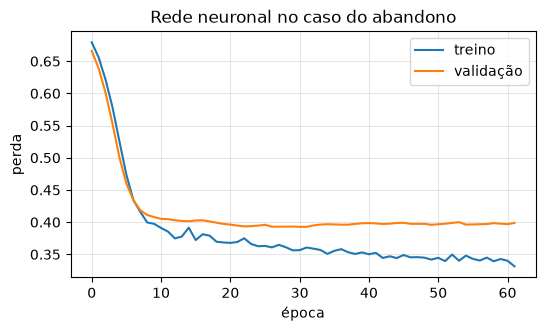

In [23]:
# Executar esta célula

torch.manual_seed(0)
n_atributos = A_treino.shape[1]
rede_cli = nn.Sequential(
    nn.Linear(n_atributos, 32), nn.ReLU(), nn.Dropout(0.2),
    nn.Linear(32, 16), nn.ReLU(),
    nn.Linear(16, 1),
).to(dispositivo)
print("Parâmetros:", sum(p.numel() for p in rede_cli.parameters()))

hist_cli = treinar(rede_cli, cli_treino_dl, cli_val_dl, nn.BCEWithLogitsLoss(),
                   torch.optim.Adam(rede_cli.parameters(), lr=1e-3, weight_decay=1e-4), epocas=500, paciencia=30)

plt.figure(figsize=(6, 3.2))
plt.plot(hist_cli["treino"], label="treino")
plt.plot(hist_cli["val"], label="validação")
plt.title("Rede neuronal no caso do abandono")
plt.xlabel("época")
plt.ylabel("perda")
plt.legend()
plt.show()

### 6.4 A comparação honesta

Comparamos a rede, **no mesmo conjunto de teste e com a mesma métrica** (AUC, como no N3_03), com dois modelos clássicos: a regressão logística (um só neurónio, afinal) e o *gradient boosting* com árvores. Os modelos clássicos treinam com o treino e a validação juntos, porque não precisam de validação para parar.


In [24]:
# Executar esta célula

A_treino_val = np.vstack([A_treino, A_val])
y_treino_val = np.concatenate([yc_treino, yc_val])

modelos_classicos = {
    "regressão logística": LogisticRegression(max_iter=1000),
    "gradient boosting": HistGradientBoostingClassifier(random_state=42),
}
aucs = {nome: roc_auc_score(yc_teste, m.fit(A_treino_val, y_treino_val).predict_proba(A_teste)[:, 1])
        for nome, m in modelos_classicos.items()}
aucs["rede neuronal (PyTorch)"] = roc_auc_score(yc_teste, prever_proba(rede_cli, A_teste))

for nome, auc in sorted(aucs.items(), key=lambda kv: -kv[1]):
    print(f"{nome:<26} AUC no teste = {auc:.3f}")

regressão logística        AUC no teste = 0.855
rede neuronal (PyTorch)    AUC no teste = 0.833
gradient boosting          AUC no teste = 0.823


A rede neuronal **não ganha** à regressão logística: o modelo mais simples é o melhor neste teste. (O *gradient boosting* fica ainda abaixo, mas está com as opções por omissão; afinado, costuma ficar ao nível dos melhores.) Não é um erro: é o resultado mais frequente em **dados tabulares** pequenos ou médios (centenas a dezenas de milhares de linhas, atributos já com significado), e está bem documentado na literatura. Nestes problemas, os modelos lineares e os de árvores costumam ser tão bons ou melhores do que as redes, e são mais rápidos, mais estáveis e mais fáceis de explicar. Repara também nas curvas: a perda de validação estabiliza em poucas dezenas de épocas, sinal de que não há muito mais para a rede aprender nestes dados.

As redes neuronais brilham quando os dados são **muitos** e **não estruturados**: imagens, som, texto, séries longas. Aí, as camadas aprendem sozinhas os atributos (bordas e formas numa imagem, palavras e frases num texto) que nenhum analista conseguiria construir à mão. É esse o tema dos próximos módulos.

> **Lição para o processo KDD (N3_03):** começa sempre por um modelo simples e por uma referência. Uma rede neuronal só se justifica se for **claramente melhor** no mesmo teste, porque traz custos: mais hiperparâmetros, mais tempo de treino e menos interpretabilidade.


## 7. Experimenta

### Exercício 1 – SGD ou Adam?

Treina a `RedeLuas` nas meias-luas durante 100 épocas com três otimizadores: `SGD(lr=0.1)`, `SGD(lr=0.1, momentum=0.9)` e `Adam(lr=0.01)`. Desenha as três curvas de perda de treino no mesmo gráfico. Qual converge mais depressa?


In [25]:
# Executar esta célula

# Escreve aqui o código do exercício 1

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
otimizadores = {
    "SGD": lambda p: torch.optim.SGD(p, lr=0.1),
    "SGD + momentum": lambda p: torch.optim.SGD(p, lr=0.1, momentum=0.9),
    "Adam": lambda p: torch.optim.Adam(p, lr=0.01),
}
for nome, criar in otimizadores.items():
    torch.manual_seed(0)
    m = RedeLuas().to(dispositivo)
    opt = criar(m.parameters())
    dl = carregador_de(X_treino, y_treino, batch_size=32, shuffle=True, generator=torch.Generator().manual_seed(0))
    perdas = [treinar_epoca(m, dl, nn.BCEWithLogitsLoss(), opt) for _ in range(100)]
    plt.plot(perdas, label=f"{nome} (final {perdas[-1]:.3f})")
plt.xlabel("época")
plt.ylabel("perda de treino")
plt.legend()
plt.show()
# O momentum e o Adam descem bastante mais depressa do que o SGD simples.
```

</details>


### Exercício 2 – Uma rede mais profunda

Define, com `nn.Sequential`, uma rede para as meias-luas com **duas** camadas escondidas de 32 neurónios e `nn.Dropout(0.2)` depois de cada uma. Treina-a com Adam (`lr=0.01`) e a função `treinar` (paragem antecipada), e compara a exatidão no teste com a `RedeLuas`. Quantos parâmetros tem cada uma?


In [26]:
# Executar esta célula

# Escreve aqui o código do exercício 2

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
torch.manual_seed(0)
profunda = nn.Sequential(
    nn.Linear(2, 32), nn.ReLU(), nn.Dropout(0.2),
    nn.Linear(32, 32), nn.ReLU(), nn.Dropout(0.2),
    nn.Linear(32, 1),
).to(dispositivo)
treinar(profunda, treino_dl, val_dl, nn.BCEWithLogitsLoss(), torch.optim.Adam(profunda.parameters(), lr=0.01))
for nome, m in [("RedeLuas (16)", modelo_adam), ("profunda (32 + 32)", profunda)]:
    n_par = sum(p.numel() for p in m.parameters())
    print(f"{nome:<20} {n_par:>5} parâmetros | exatidão no teste {avaliar(m, teste_dl, nn.BCEWithLogitsLoss())[1]:.1%}")
# Com tão poucos dados e um problema tão simples, a rede maior não traz ganho visível:
# mais capacidade só ajuda quando os dados a justificam.
```

</details>


### Exercício 3 – Regressão com PyTorch

Uma rede neuronal também prevê números. Gera 200 pontos de $y = \sin(x) + \text{ruído}$, com $x$ entre −3 e 3, treina uma rede `1 → 32 → 32 → 1` (ReLU) com `nn.MSELoss()` e Adam durante 500 épocas (podes usar todos os dados num só lote), e desenha os pontos e a curva aprendida.


In [27]:
# Executar esta célula

# Escreve aqui o código do exercício 3

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
rng = np.random.default_rng(0)
x_np = rng.uniform(-3, 3, size=(200, 1))
y_np = np.sin(x_np) + rng.normal(0, 0.15, size=(200, 1))
x_t, y_t = torch.tensor(x_np, dtype=torch.float32), torch.tensor(y_np, dtype=torch.float32)

torch.manual_seed(0)
regressor = nn.Sequential(nn.Linear(1, 32), nn.ReLU(), nn.Linear(32, 32), nn.ReLU(), nn.Linear(32, 1))
opt = torch.optim.Adam(regressor.parameters(), lr=0.01)
mse = nn.MSELoss()
for epoca in range(500):
    perda = mse(regressor(x_t), y_t)
    opt.zero_grad()
    perda.backward()
    opt.step()
print(f"Erro quadrático médio final: {perda.item():.4f} (variância do ruído: {0.15 ** 2:.4f})")

grelha = torch.linspace(-3, 3, 200).reshape(-1, 1)
regressor.eval()
with torch.no_grad():
    curva = regressor(grelha)
plt.scatter(x_np, y_np, s=10, alpha=0.5, label="dados")
plt.plot(grelha.numpy(), curva.numpy(), color="C3", lw=2, label="rede")
plt.plot(grelha.numpy(), np.sin(grelha.numpy()), "k--", lw=1, label="sin(x)")
plt.legend()
plt.show()
```

</details>


## Verifica o que aprendeste

1. Que três diferenças importantes há entre um tensor e um *array* do NumPy?
2. Porque é que `torch.from_numpy(a)` pode dar problemas com o tipo de dados, e como se resolve?
3. O que fazem `requires_grad=True` e `backward()`? Porque é que é preciso `zero_grad()` em cada passo?
4. Porque é que a última camada não tem sigmoide quando se usa `nn.BCEWithLogitsLoss`?
5. Quais são as cinco linhas de um passo de treino?
6. Que dois métodos tem um `Dataset`, e o que faz o `DataLoader`?
7. Para que servem `modelo.eval()` e `torch.no_grad()`, e porque se usam juntos?
8. No caso do abandono, a rede neuronal não ganhou à regressão logística. Porquê, e em que tipo de dados se espera que as redes ganhem?

<details>
<summary><b>Ver respostas</b></summary>

1. Os tensores podem estar na GPU, registam as operações para calcular gradientes (*autograd*), e usam `float32` por omissão (o NumPy usa `float64`).
2. Porque o tensor herda o `float64` do NumPy e as camadas usam `float32`, o que dá `RuntimeError`. Resolve-se convertendo: `torch.tensor(X, dtype=torch.float32)` ou `.float()`.
3. `requires_grad=True` faz o tensor registar as operações; `backward()` percorre esse registo de trás para a frente e guarda as derivadas em `.grad`. Como os gradientes se somam a cada `backward()`, têm de ser postos a zero antes de cada passo.
4. Porque essa função de perda aplica a sigmoide internamente, de forma numericamente mais estável. Para obter probabilidades, aplica-se `torch.sigmoid` à saída.
5. `logits = modelo(X)`, `perda = perda_fn(logits, y)`, `otimizador.zero_grad()`, `perda.backward()`, `otimizador.step()`.
6. `__len__` (quantos exemplos) e `__getitem__` (o exemplo `i`). O `DataLoader` entrega os exemplos em mini-lotes, baralhados se `shuffle=True`.
7. `eval()` põe as camadas como o *dropout* em modo de avaliação; `no_grad()` desliga o registo do grafo, poupando memória e tempo. Juntos, garantem previsões corretas e eficientes.
8. Em dados tabulares pequenos, com atributos já construídos, os modelos lineares e de árvores costumam ser tão bons ou melhores. As redes ganham com muitos dados não estruturados (imagens, som, texto), onde aprendem sozinhas os atributos.

</details>

## Leitura recomendada

- [Tutoriais oficiais do PyTorch: *Learn the Basics*](https://pytorch.org/tutorials/beginner/basics/intro.html). Tensores, `Dataset` e `DataLoader`, `nn.Module`, *autograd*, otimização e guardar modelos, pela mesma ordem deste módulo.
- Stevens, E., Antiga, L. e Viehmann, T. (2020). *[Deep Learning with PyTorch](https://www.manning.com/books/deep-learning-with-pytorch)*. Shelter Island, NY: Manning.
- Raschka, S., Liu, Y. e Mirjalili, V. (2022). *Machine Learning with PyTorch and Scikit-Learn*. Birmingham: Packt. Os capítulos 12 a 14 fazem a ponte entre o scikit-learn e o PyTorch.
- Zhang, A., Lipton, Z. C., Li, M. e Smola, A. J. (2023). *[Dive into Deep Learning](https://d2l.ai/)*. Cambridge University Press. Livro gratuito em linha, com código em PyTorch.
- Grinsztajn, L., Oyallon, E. e Varoquaux, G. (2022). «[Why do tree-based models still outperform deep learning on typical tabular data?](https://arxiv.org/abs/2207.08815)». *NeurIPS 2022, Datasets and Benchmarks Track*. O estudo por trás da conclusão da secção 6.4.
- **Módulos relacionados:** N3_03 (o processo KDD e o caso do abandono) e N3_04 (redes neuronais de raiz).
